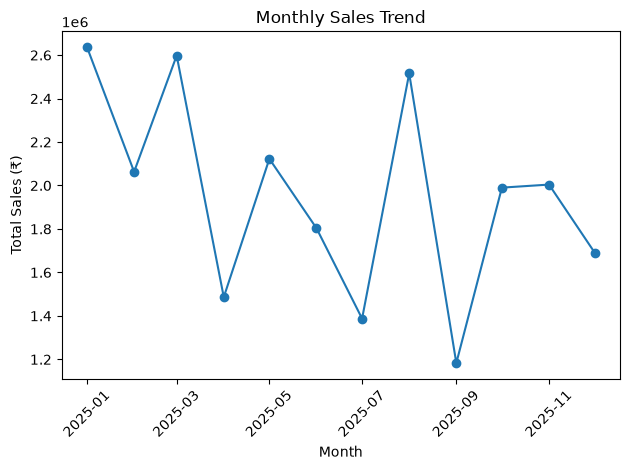

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('data1.csv')     
data['OrderDate'] = pd.to_datetime(data['OrderDate'])       # Changes the data inside your Python program, not the original CSV file automatically
data = data.sort_values("OrderDate")

monthly_sales = data.groupby(                               # by month
    data['OrderDate'].dt.to_period('M')
)['Sales'].sum()

plt.plot(                                                   # Plotting the monthly sales data
    monthly_sales.index.to_timestamp(),
    monthly_sales.values,
    marker='o'
)
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.title('Monthly Sales Trend')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

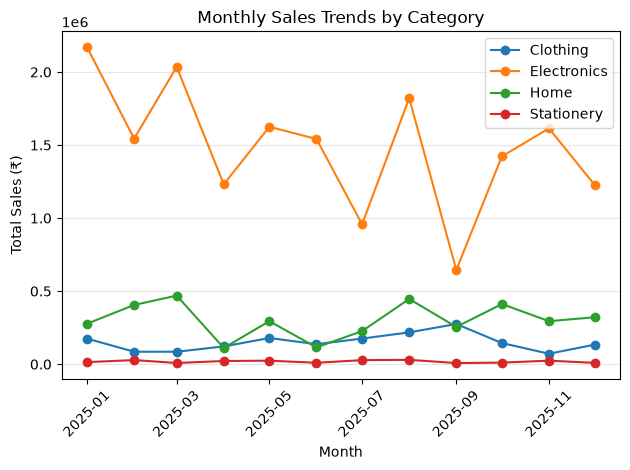

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('data1.csv')     
data['OrderDate'] = pd.to_datetime(data['OrderDate'])

monthly_category_sales = data.groupby(
    [data['OrderDate'].dt.to_period('M'), 'Category']       # Group by Month and Category
)['Sales'].sum()
monthly_category_sales = monthly_category_sales.unstack()   # Reshape the data for plotting

plt.plot(monthly_category_sales.index.to_timestamp(),       # Plotting the monthly sales data by category
         monthly_category_sales.values,
         marker='o')

plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.title('Monthly Sales Trends by Category')
plt.legend(monthly_category_sales.columns)                  # Add legend
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

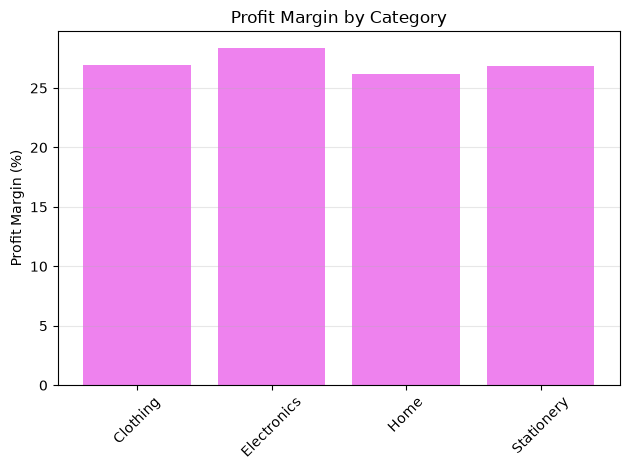

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

data = pd.read_csv('data1.csv')
data['OrderDate'] = pd.to_datetime(data['OrderDate'])

category_performance = data.groupby('Category')[['Sales', 'Profit']].sum()      # Group by Category, added their sales and profit (as they were scattered as same catagory with different entries)
category_performance['Profit_Margin'] = (                                       # Calculate Profit Margin: profit/sales*100
    category_performance['Profit'] /
    category_performance['Sales']
) * 100

plt.bar(category_performance.index, category_performance['Profit_Margin'], color='violet')      # Plot Profit Margin by Category
plt.ylabel('Profit Margin (%)')
plt.title('Profit Margin by Category')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()